# Superstore Sales Analysis
**Goal:** understand customer purchase volume, monthly seasonality, category-wise revenue and discount sensitivity, then turn it into executive takeaways.

**Flow:** 1. Load & clean → 2. Aggregate (Category / Region / Segment) → 3. Seasonality & sales velocity → 4. Customer purchase volume → 5. Discount sensitivity → 6. Executive takeaways

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
pd.options.display.float_format = "{:,.2f}".format

## 1. Load & clean the data

The CSV has a quirk: below the 9,994 order rows, two small extra tables (a *People* table and a *Returns* table) are appended in the same file. They show up as ~800 rows full of nulls. I'll separate them out first instead of blindly dropping nulls.

In [2]:
raw = pd.read_csv("superstore_sales.csv", encoding="latin-1")
print("Raw shape:", raw.shape)
print("\nNulls per column:")
print(raw.isna().sum()[raw.isna().sum() > 0])

Raw shape: (10800, 21)

Nulls per column:
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64


In [3]:
# Real orders = rows with an Order Date. The rest are the appended People / Returns tables.
df = raw[raw["Order Date"].notna()].copy()
returns = raw.loc[raw["Row ID"] == "Yes", "Order ID"].drop_duplicates()   # returned order IDs (kept for reference)
print(f"Order rows: {len(df):,} | stray rows removed: {len(raw) - len(df):,} | returned orders listed: {len(returns):,}")

Order rows: 9,994 | stray rows removed: 806 | returned orders listed: 296


In [4]:
# Fix data types
df["Row ID"] = df["Row ID"].astype(int)
df["Quantity"] = df["Quantity"].astype(int)
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")

# Remaining nulls: only Postal Code (Burlington, VT) -> fill with its known ZIP
print("Remaining nulls:", df.isna().sum()[df.isna().sum() > 0].to_dict())
df["Postal Code"] = df["Postal Code"].fillna(5401).astype(int)

# Duplicates (ignoring the Row ID counter)
dupes = df.duplicated(subset=[c for c in df.columns if c != "Row ID"]).sum()
print("Duplicate rows:", dupes)
df = df.drop_duplicates(subset=[c for c in df.columns if c != "Row ID"])

# Date features
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Year-Month"] = df["Order Date"].dt.to_period("M").dt.to_timestamp()
df["Margin"] = df["Profit"] / df["Sales"]

print("\nFinal shape:", df.shape)
print("Date range:", df["Order Date"].min().date(), "to", df["Order Date"].max().date())
df.head()

Remaining nulls: {'Postal Code': 11}
Duplicate rows: 1

Final shape: (9993, 25)
Date range: 2015-01-03 to 2018-12-30


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Year-Month,Margin
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91,2017,11,2017-11-01,0.16
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58,2017,11,2017-11-01,0.30
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.87,2017,6,2017-06-01,0.47
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5,0.45,-383.03,2016,10,2016-10-01,-0.40
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Storage,Eldon Fold 'N Roll Cart System,22.37,2,0.20,2.52,2016,10,2016-10-01,0.11


In [5]:
df[["Sales", "Quantity", "Discount", "Profit"]].describe()

,Sales,Quantity,Discount,Profit
count,"9,993.00","9,993.00","9,993.00","9,993.00"
mean,229.85,3.79,0.16,28.66
std,623.28,2.23,0.21,234.27
min,0.44,1.00,0.00,"-6,599.98"
25%,17.28,2.00,0.00,1.73
50%,54.48,3.00,0.20,8.67
75%,209.94,5.00,0.20,29.36
max,"22,638.48",14.00,0.80,"8,399.98"


## 2. Aggregate Sales & Profit: Category, Region, Segment

In [6]:
def agg(by):
    g = df.groupby(by).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique"))
    g["Margin %"] = g["Profit"] / g["Sales"] * 100
    return g.sort_values("Sales", ascending=False)

for col in ["Category", "Region", "Segment"]:
    display(agg(col))

,Sales,Profit,Orders,Margin %
Category,,,,
Technology,"836,154.03","145,454.95",1544,17.40
Furniture,"741,718.42","18,463.33",1764,2.49
Office Supplies,"719,047.03","122,490.80",3742,17.04


,Sales,Profit,Orders,Margin %
Region,,,,
West,"725,457.82","108,418.45",1611,14.94
East,"678,499.87","91,534.84",1401,13.49
Central,"501,239.89","39,706.36",1175,7.92
South,"391,721.91","46,749.43",822,11.93


,Sales,Profit,Orders,Margin %
Segment,,,,
Consumer,"1,161,401.34","134,119.21",2586,11.55
Corporate,"706,146.37","91,979.13",1514,13.03
Home Office,"429,371.78","60,310.74",909,14.05


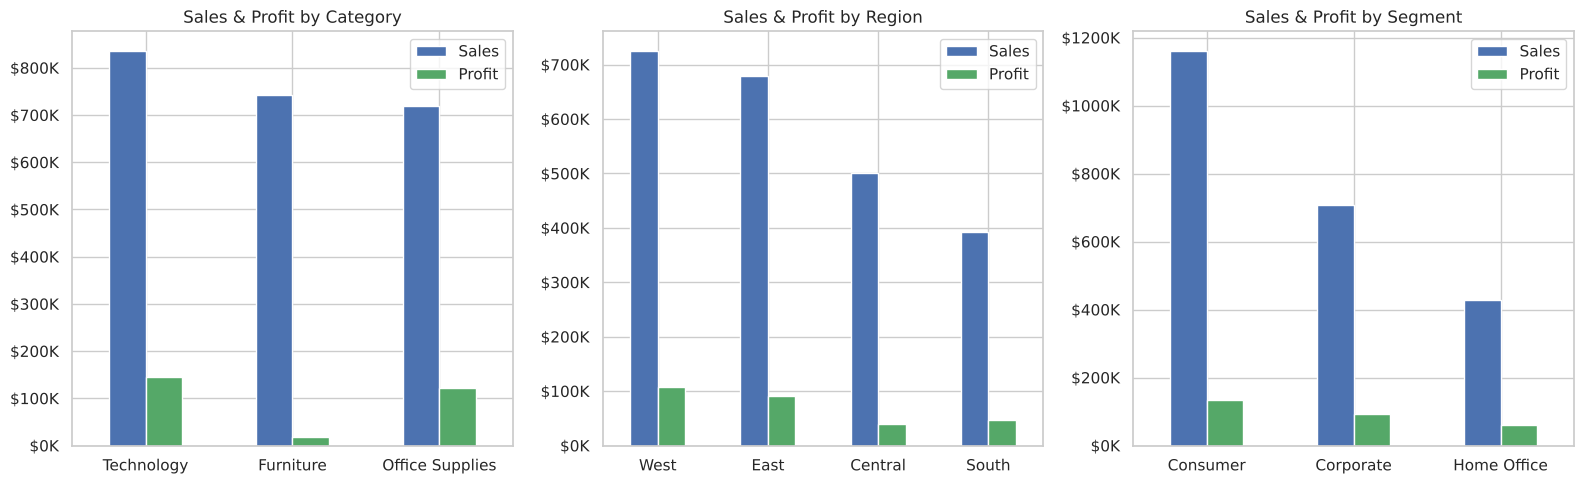

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, ["Category", "Region", "Segment"]):
    g = agg(col)[["Sales", "Profit"]]
    g.plot(kind="bar", ax=ax, color=["#4C72B0", "#55A868"], rot=0)
    ax.set_title(f"Sales & Profit by {col}"); ax.set_xlabel("")
    ax.yaxis.set_major_formatter(lambda x, p: f"${x/1000:.0f}K")
plt.tight_layout(); plt.show()

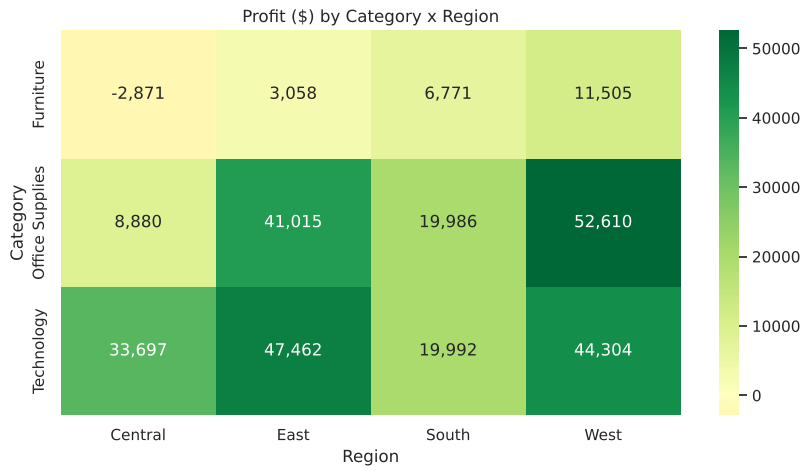

In [8]:
# Where does profit actually come from? Category x Region
pivot = df.pivot_table(values="Profit", index="Category", columns="Region", aggfunc="sum")
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="RdYlGn", center=0)
plt.title("Profit ($) by Category x Region"); plt.show()

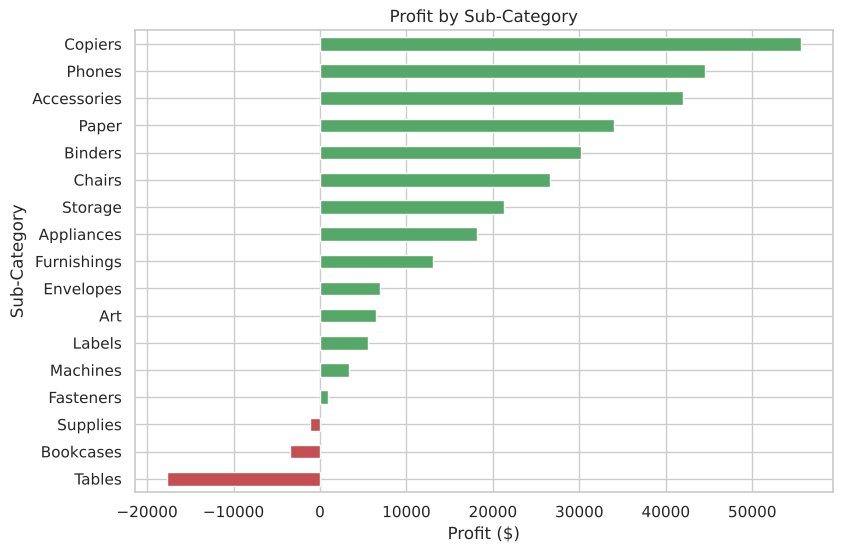

In [9]:
sub = df.groupby("Sub-Category")[["Sales", "Profit"]].sum().sort_values("Profit")
colors = ["#C44E52" if p < 0 else "#55A868" for p in sub["Profit"]]
sub["Profit"].plot(kind="barh", color=colors, figsize=(9, 6))
plt.title("Profit by Sub-Category"); plt.xlabel("Profit ($)"); plt.show()

## 3. Monthly seasonality & sales velocity

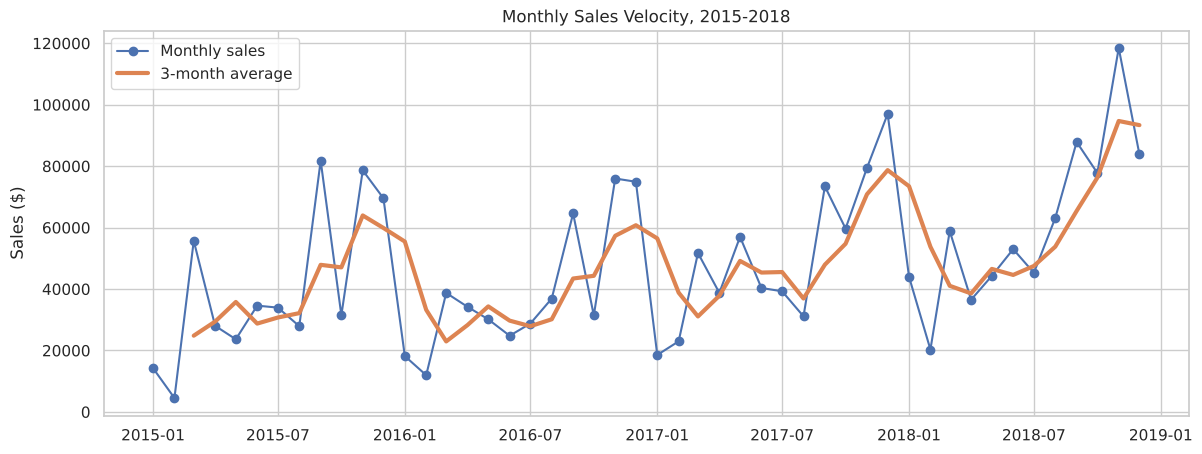

In [10]:
monthly = df.groupby("Year-Month")[["Sales", "Profit"]].sum()
monthly["Sales (3M avg)"] = monthly["Sales"].rolling(3).mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(monthly.index, monthly["Sales"], marker="o", label="Monthly sales")
ax.plot(monthly.index, monthly["Sales (3M avg)"], linewidth=3, label="3-month average")
ax.set_title("Monthly Sales Velocity, 2015-2018"); ax.set_ylabel("Sales ($)")
ax.legend(); plt.show()

In [11]:
yearly = df.groupby("Year")[["Sales", "Profit"]].sum()
yearly["Sales growth %"] = yearly["Sales"].pct_change() * 100
yearly["Margin %"] = yearly["Profit"] / yearly["Sales"] * 100
yearly

,Sales,Profit,Sales growth %,Margin %
Year,,,,
2015,"483,966.13","49,556.03",NaN,10.24
2016,"470,532.51","61,618.60",-2.78,13.10
2017,"609,205.60","81,795.17",29.47,13.43
2018,"733,215.26","93,439.27",20.36,12.74


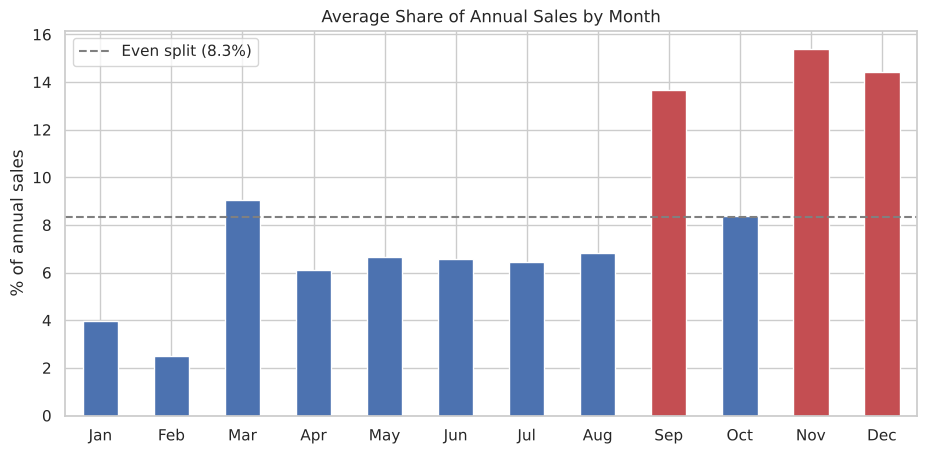

Sep + Nov + Dec = 43.5% of annual sales


In [12]:
# Seasonality: share of annual sales by calendar month (averaged over years)
season = df.groupby(["Year", "Month"])["Sales"].sum().unstack("Month")
share = season.div(season.sum(axis=1), axis=0).mean() * 100
share.index = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

ax = share.plot(kind="bar", color=["#C44E52" if v > 10 else "#4C72B0" for v in share], rot=0, figsize=(11, 5))
ax.axhline(100/12, ls="--", color="grey", label="Even split (8.3%)")
ax.set_title("Average Share of Annual Sales by Month"); ax.set_ylabel("% of annual sales"); ax.legend()
plt.show()
print(f"Sep + Nov + Dec = {share[['Sep','Nov','Dec']].sum():.1f}% of annual sales")

## 4. Customer purchase volume

Customers: 793 | avg orders/customer: 6.3 | avg lifetime sales: $2,896
Top 20% of customers generate 48% of sales


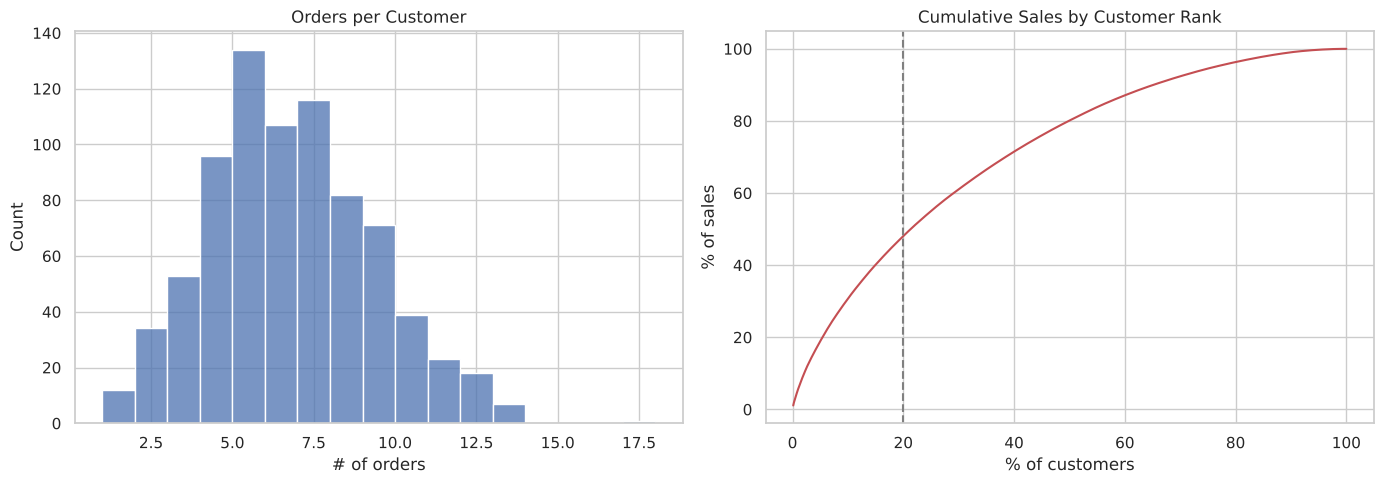

,Orders,Sales,Profit
Customer ID,,,
SM-20320,5,"25,043.05","-1,980.74"
TC-20980,5,"19,052.22","8,981.32"
RB-19360,6,"15,117.34","6,976.10"
TA-21385,4,"14,595.62","4,703.79"
AB-10105,10,"14,473.57","5,444.81"
KL-16645,12,"14,175.23",806.86
SC-20095,9,"14,142.33","5,757.41"
HL-15040,6,"12,873.30","5,622.43"
SE-20110,11,"12,209.44","2,650.68"


In [13]:
cust = df.groupby("Customer ID").agg(Orders=("Order ID", "nunique"), Sales=("Sales", "sum"), Profit=("Profit", "sum"))
print(f"Customers: {len(cust)} | avg orders/customer: {cust['Orders'].mean():.1f} | avg lifetime sales: ${cust['Sales'].mean():,.0f}")

top20 = cust["Sales"].nlargest(int(len(cust) * 0.2)).sum() / cust["Sales"].sum()
print(f"Top 20% of customers generate {top20:.0%} of sales")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(cust["Orders"], bins=range(1, 19), ax=axes[0], color="#4C72B0")
axes[0].set_title("Orders per Customer"); axes[0].set_xlabel("# of orders")

pareto = cust["Sales"].sort_values(ascending=False).cumsum() / cust["Sales"].sum() * 100
axes[1].plot(np.arange(1, len(pareto) + 1) / len(pareto) * 100, pareto.values, color="#C44E52")
axes[1].axvline(20, ls="--", color="grey"); axes[1].set_title("Cumulative Sales by Customer Rank")
axes[1].set_xlabel("% of customers"); axes[1].set_ylabel("% of sales")
plt.tight_layout(); plt.show()

cust.nlargest(10, "Sales")

## 5. Discount sensitivity

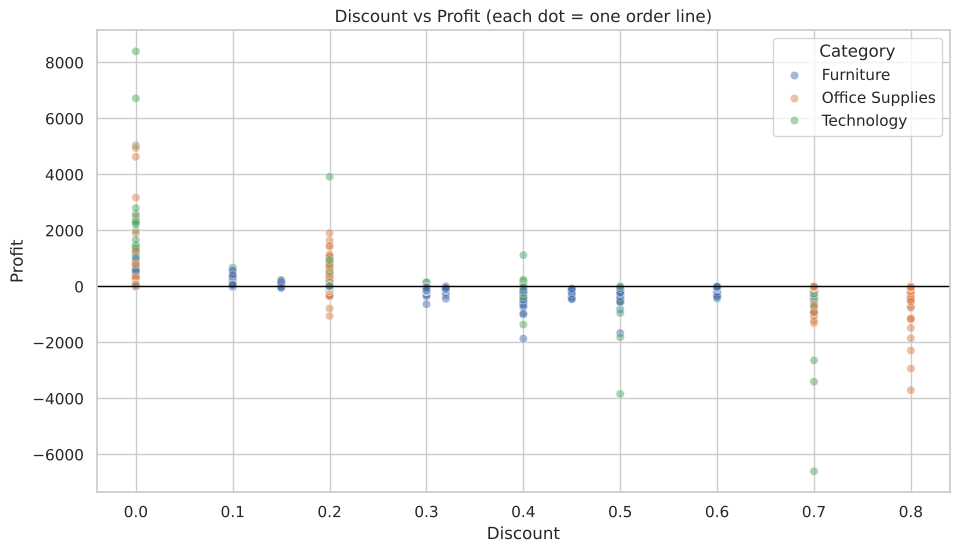

Correlation (Discount vs Profit): -0.219
Correlation (Discount vs Margin): -0.864


In [14]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(data=df, x="Discount", y="Profit", hue="Category", alpha=0.5, ax=ax)
ax.axhline(0, color="black", lw=1)
ax.set_title("Discount vs Profit (each dot = one order line)")
plt.show()

print("Correlation (Discount vs Profit):", round(df["Discount"].corr(df["Profit"]), 3))
print("Correlation (Discount vs Margin):", round(df["Discount"].corr(df["Margin"]), 3))

,Lines,Sales,Profit,Margin %
Discount Band,,,,
0%,4798,"1,087,908.47","320,987.60",29.51
1-10%,94,"54,369.35","9,029.18",16.61
11-20%,3709,"792,152.89","91,756.30",11.58
21-30%,226,"102,945.28","-10,357.22",-10.06
31-40%,233,"130,911.24","-25,448.19",-19.44
41-50%,77,"64,403.51","-22,999.54",-35.71
>50%,856,"64,228.74","-76,559.05",-119.20


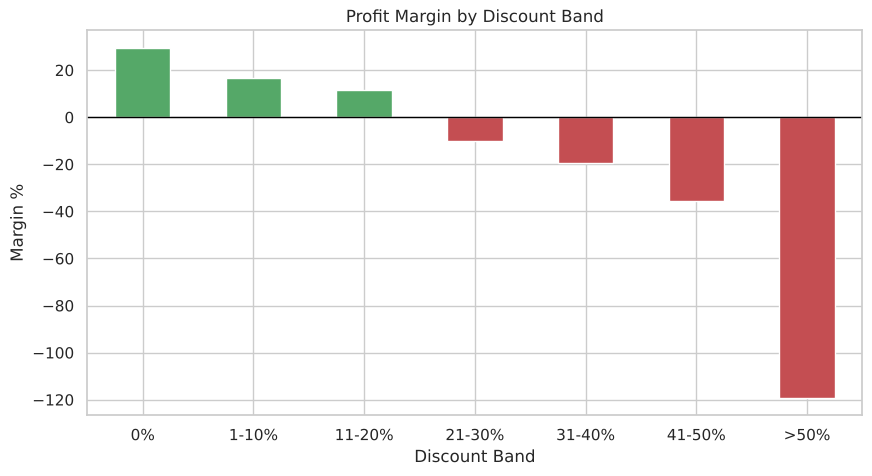

In [15]:
bins = [-0.01, 0, 0.10, 0.20, 0.30, 0.40, 0.50, 1.0]
labels = ["0%", "1-10%", "11-20%", "21-30%", "31-40%", "41-50%", ">50%"]
df["Discount Band"] = pd.cut(df["Discount"], bins=bins, labels=labels)

band = df.groupby("Discount Band", observed=True).agg(Lines=("Sales", "size"), Sales=("Sales", "sum"), Profit=("Profit", "sum"))
band["Margin %"] = band["Profit"] / band["Sales"] * 100
display(band)

colors = ["#C44E52" if m < 0 else "#55A868" for m in band["Margin %"]]
band["Margin %"].plot(kind="bar", color=colors, rot=0, figsize=(10, 5))
plt.axhline(0, color="black", lw=1); plt.title("Profit Margin by Discount Band"); plt.ylabel("Margin %"); plt.show()

In [16]:
# Which categories are hurt most by discounting?
heavy = df[df["Discount"] > 0.2]
display(heavy.groupby("Category")[["Sales", "Profit"]].sum())
print(f"Orders discounted >20%: {len(heavy):,} lines ({len(heavy)/len(df):.0%} of all) | total profit on them: ${heavy['Profit'].sum():,.0f}")

,Sales,Profit
Category,,
Furniture,"194,869.37","-54,465.70"
Office Supplies,"39,523.15","-47,140.14"
Technology,"128,096.26","-33,758.16"


Orders discounted >20%: 1,392 lines (14% of all) | total profit on them: $-135,364


## 6. Executive takeaways

1. **Growth is real and profitability is improving.** Sales rose from ~$484K (2015) to ~$733K (2018), +51%, and profit almost doubled from ~$49.5K to ~$93.4K, lifting margin from ~10.2% to ~12.7%. *Action: keep the current growth levers; the business is scaling without losing margin.*

2. **Sales are heavily seasonal, with a Q4 and September surge.** September, November and December together deliver ~43% of annual sales, while February (~2.6%) and January (~4.1%) are the weakest months. *Action: build inventory and staffing ahead of Sep-Dec, and use Jan-Feb for promotions or B2B outreach to smooth demand.*

3. **Technology and Office Supplies drive profit; Furniture does not.** Furniture brings in ~$742K sales, nearly as much as Technology (~$836K), but earns only ~$18K profit (2.5% margin) versus ~17% for the other two categories. Tables (-$17.7K) and Bookcases (-$3.5K) are loss-making sub-categories. *Action: re-price or reduce discounts on Tables and Bookcases; push Copiers, Phones and Accessories.*

4. **Discounting above 20% destroys profit.** Undiscounted lines earn a ~29.5% margin and 11-20% discounts still earn ~11.6%, but every band above 20% runs at a loss, and the >50% band loses ~$76.6K on ~$64K of sales (margin about -119%). Discount and profit are negatively correlated. *Action: cap discounts at 20% and require approval beyond that.*

5. **The Central region under-performs.** Central brings in ~$501K in sales but only ~7.9% margin (vs ~14.9% in West and ~13.5% in East), and Furniture actually loses money there (about -$2.9K). *Action: review discounting and product mix in Central first.*

6. **Customers are loyal and concentrated.** The 793 customers place ~6.3 orders each on average, and the top 20% generate ~48% of sales. Consumer is half of revenue (~$1.16M), but Home Office and Corporate earn higher margins (~14% and ~13% vs ~11.5%). *Action: protect and reward top customers with loyalty perks rather than discounts, and grow the higher-margin Corporate / Home Office segments.*